In [3]:
# If needed, run this in a notebook cell:
# %pip install pandas numpy matplotlib seaborn scikit-learn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


In [7]:
# Change this path if your CSV file is named or located differently.
DATA_PATH = "D:\python\fire.csv"

df = pd.read_csv(r"D:\python\fire.csv")
print("Dataset loaded successfully.")
print("Rows and columns:", df.shape)
display(df.head())

Dataset loaded successfully.
Rows and columns: (517, 13)


,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
0,7,5,mar,fri,86.2,26.2,94.3,5.1,8.2,51,6.7,0.0,0.0
1,7,4,oct,tue,90.6,35.4,669.1,6.7,18.0,33,0.9,0.0,0.0
2,7,4,oct,sat,90.6,43.7,686.9,6.7,14.6,33,1.3,0.0,0.0
3,8,6,mar,fri,91.7,33.3,77.5,9.0,8.3,97,4.0,0.2,0.0
4,8,6,mar,sun,89.3,51.3,102.2,9.6,11.4,99,1.8,0.0,0.0


## 3. Explore and inspect the data

In [8]:
print("Column names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nMissing values per column:")
display(df.isnull().sum().sort_values(ascending=False).to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())
print("\nSummary statistics:")
display(df.describe(include="all").T)

Column names:
['X', 'Y', 'month', 'day', 'FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH', 'wind', 'rain', 'area']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X       517 non-null    int64  
 1   Y       517 non-null    int64  
 2   month   517 non-null    str    
 3   day     517 non-null    str    
 4   FFMC    517 non-null    float64
 5   DMC     517 non-null    float64
 6   DC      517 non-null    float64
 7   ISI     517 non-null    float64
 8   temp    517 non-null    float64
 9   RH      517 non-null    int64  
 10  wind    517 non-null    float64
 11  rain    517 non-null    float64
 12  area    517 non-null    float64
dtypes: float64(8), int64(3), str(2)
memory usage: 52.6 KB

Missing values per column:


,Missing Values
X,0
Y,0
month,0
day,0
FFMC,0
DMC,0
DC,0
ISI,0
temp,0
RH,0



Duplicate rows: 4

Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
X,517.0,NaN,NaN,NaN,4.669246,2.313778,1.0,3.0,4.0,7.0,9.0
Y,517.0,NaN,NaN,NaN,4.299807,1.2299,2.0,4.0,4.0,5.0,9.0
month,517,12,aug,184,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,517,7,sun,95,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FFMC,517.0,NaN,NaN,NaN,90.644681,5.520111,18.7,90.2,91.6,92.9,96.2
DMC,517.0,NaN,NaN,NaN,110.87234,64.046482,1.1,68.6,108.3,142.4,291.3
DC,517.0,NaN,NaN,NaN,547.940039,248.066192,7.9,437.7,664.2,713.9,860.6
ISI,517.0,NaN,NaN,NaN,9.021663,4.559477,0.0,6.5,8.4,10.8,56.1
temp,517.0,NaN,NaN,NaN,18.889168,5.806625,2.2,15.5,19.3,22.8,33.3
RH,517.0,NaN,NaN,NaN,44.288201,16.317469,15.0,33.0,42.0,53.0,100.0


## 4. Clean data and select the target column

The target is the column the model must predict (for example, `Fire_Risk`, `Risk_Level`, or `Class`). The code checks common target names. **Review the selected column before continuing.**

In [10]:
# Display all column names
print("Column Names:")
print(df.columns.tolist())

# Display first 5 rows
display(df.head())

Column Names:
['X', 'Y', 'month', 'day', 'FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH', 'wind', 'rain', 'area']


,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
0,7,5,mar,fri,86.2,26.2,94.3,5.1,8.2,51,6.7,0.0,0.0
1,7,4,oct,tue,90.6,35.4,669.1,6.7,18.0,33,0.9,0.0,0.0
2,7,4,oct,sat,90.6,43.7,686.9,6.7,14.6,33,1.3,0.0,0.0
3,8,6,mar,fri,91.7,33.3,77.5,9.0,8.3,97,4.0,0.2,0.0
4,8,6,mar,sun,89.3,51.3,102.2,9.6,11.4,99,1.8,0.0,0.0


In [12]:
# Remove exact duplicate rows
df = df.drop_duplicates().copy()

# Strip spaces from column names
df.columns = df.columns.astype(str).str.strip()

# Create target column using area
df["Fire_Risk"] = df["area"].apply(
    lambda x: "Fire" if x > 0 else "No_Fire"
)

# Set target column manually
TARGET_COLUMN = "Fire_Risk"

print("Selected target column:", TARGET_COLUMN)
print("\nTarget value counts:")

display(df[TARGET_COLUMN].value_counts(dropna=False).to_frame("Count"))

# Remove rows with missing target labels
df = df.dropna(subset=[TARGET_COLUMN]).copy()

# Check target classes
if df[TARGET_COLUMN].nunique() < 2:
    raise ValueError("Target column has fewer than 2 classes.")

print("Dataset shape after basic cleaning:", df.shape)

Selected target column: Fire_Risk

Target value counts:


,Count
Fire_Risk,
Fire,269
No_Fire,244


Dataset shape after basic cleaning: (513, 14)


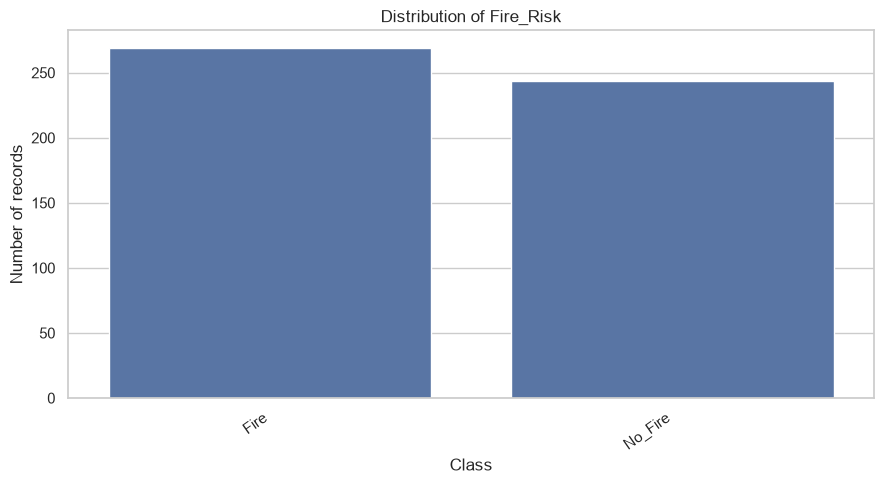

In [13]:
plt.figure(figsize=(9, 5))
order = df[TARGET_COLUMN].astype(str).value_counts().index
sns.countplot(data=df, x=df[TARGET_COLUMN].astype(str), order=order)
plt.title(f"Distribution of {TARGET_COLUMN}")
plt.xlabel("Class")
plt.ylabel("Number of records")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [14]:
X = df.drop(columns=[TARGET_COLUMN]).copy()
y_raw = df[TARGET_COLUMN].astype(str)

# Remove columns with only one unique non-null value; they cannot help distinguish classes.
constant_cols = [c for c in X.columns if X[c].nunique(dropna=False) <= 1]
if constant_cols:
    print("Removing constant feature columns:", constant_cols)
    X = X.drop(columns=constant_cols)

if X.shape[1] == 0:
    raise ValueError("No usable input features remain after removing the target and constant columns.")

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)
class_names = label_encoder.classes_
print("Features:", X.columns.tolist())
print("Classes:", list(class_names))

numeric_features = X.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

transformers = []
if numeric_features:
    transformers.append(("num", numeric_pipeline, numeric_features))
if categorical_features:
    transformers.append(("cat", categorical_pipeline, categorical_features))

preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Features: ['X', 'Y', 'month', 'day', 'FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH', 'wind', 'rain', 'area']
Classes: ['Fire', 'No_Fire']
Numeric features: ['X', 'Y', 'FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH', 'wind', 'rain', 'area']
Categorical features: ['month', 'day']


In [15]:
# Stratify where possible so classes are represented in both splits.
class_counts = pd.Series(y).value_counts()
stratify_y = y if class_counts.min() >= 2 else None

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=stratify_y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 410
Testing rows: 103


In [16]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE, class_weight="balanced"
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Support Vector Machine": SVC(class_weight="balanced")
}

trained_models = {}
results = []

for name, classifier in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])
    try:
        pipeline.fit(X_train, y_train)
        predictions = pipeline.predict(X_test)

        trained_models[name] = pipeline
        results.append({
            "Model": name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision (weighted)": precision_score(y_test, predictions, average="weighted", zero_division=0),
            "Recall (weighted)": recall_score(y_test, predictions, average="weighted", zero_division=0),
            "F1-score (weighted)": f1_score(y_test, predictions, average="weighted", zero_division=0)
        })
        print(f"Finished: {name}")
    except Exception as e:
        print(f"Could not train {name}: {e}")

results_df = pd.DataFrame(results).sort_values("F1-score (weighted)", ascending=False).reset_index(drop=True)
display(results_df.style.format({
    "Accuracy": "{:.3f}",
    "Precision (weighted)": "{:.3f}",
    "Recall (weighted)": "{:.3f}",
    "F1-score (weighted)": "{:.3f}"
}))

Finished: Logistic Regression
Finished: Decision Tree
Finished: Random Forest
Finished: K-Nearest Neighbors
Finished: Support Vector Machine


,Model,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted)
0,Decision Tree,1.000,1.000,1.000,1.000
1,Random Forest,1.000,1.000,1.000,1.000
2,Logistic Regression,0.709,0.760,0.709,0.698
3,K-Nearest Neighbors,0.602,0.601,0.602,0.601
4,Support Vector Machine,0.573,0.580,0.573,0.571


## 9. Compare model accuracy with a graph

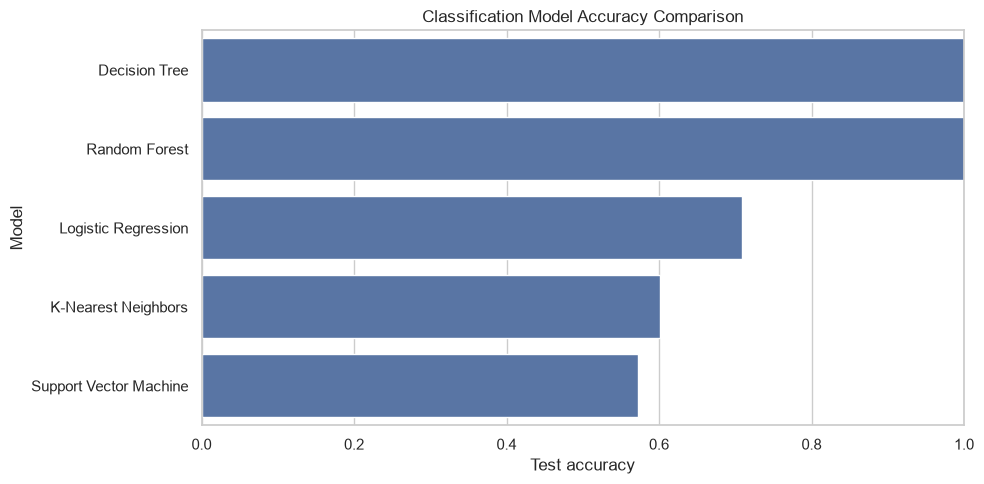

In [17]:
if results_df.empty:
    raise ValueError("No model trained successfully. Check your data and target column.")

plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Accuracy", y="Model")
plt.xlim(0, 1)
plt.title("Classification Model Accuracy Comparison")
plt.xlabel("Test accuracy")
plt.ylabel("Model")
plt.tight_layout()
plt.show()

Best model based on weighted F1-score: Decision Tree

Classification report:
              precision    recall  f1-score   support

        Fire       1.00      1.00      1.00        54
     No_Fire       1.00      1.00      1.00        49

    accuracy                           1.00       103
   macro avg       1.00      1.00      1.00       103
weighted avg       1.00      1.00      1.00       103



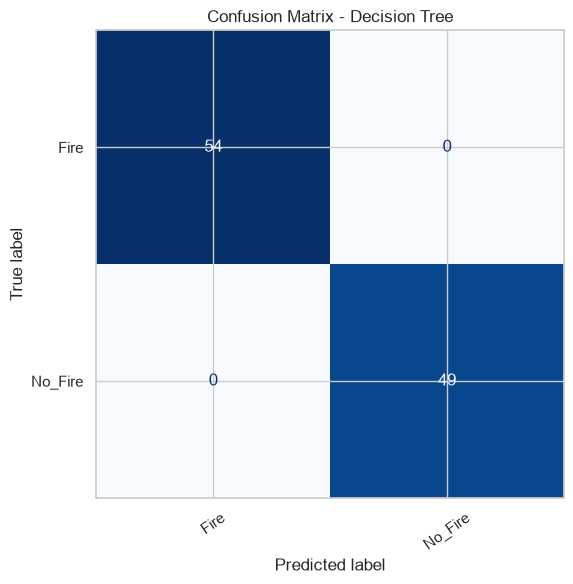

In [18]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
y_pred = best_model.predict(X_test)

print("Best model based on weighted F1-score:", best_model_name)
print("\nClassification report:")
print(classification_report(
    y_test, y_pred,
    labels=np.arange(len(class_names)),
    target_names=[str(c) for c in class_names],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred, labels=np.arange(len(class_names)))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d", xticks_rotation=35, colorbar=False)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

,Actual Class,Predicted Class
0,Fire,Fire
1,No_Fire,No_Fire
2,Fire,Fire
3,Fire,Fire
4,No_Fire,No_Fire
5,Fire,Fire
6,No_Fire,No_Fire
7,Fire,Fire
8,Fire,Fire
9,No_Fire,No_Fire


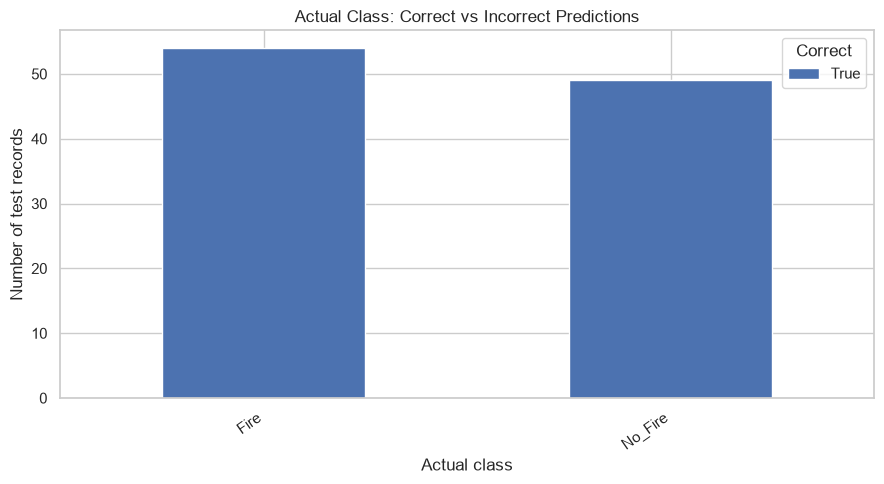

In [19]:
comparison = pd.DataFrame({
    "Actual Class": label_encoder.inverse_transform(y_test),
    "Predicted Class": label_encoder.inverse_transform(y_pred)
})
display(comparison.head(20))

comparison_counts = (
    comparison.assign(Correct=comparison["Actual Class"] == comparison["Predicted Class"])
    .groupby(["Actual Class", "Correct"]).size().unstack(fill_value=0)
)
comparison_counts.plot(kind="bar", figsize=(9, 5))
plt.title("Actual Class: Correct vs Incorrect Predictions")
plt.xlabel("Actual class")
plt.ylabel("Number of test records")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

,Feature,Importance
10,num__area,0.758952
6,num__temp,0.032520
7,num__RH,0.029050
3,num__DMC,0.025452
4,num__DC,0.023279
2,num__FFMC,0.020086
8,num__wind,0.020043
0,num__X,0.019144
5,num__ISI,0.017608
1,num__Y,0.013901


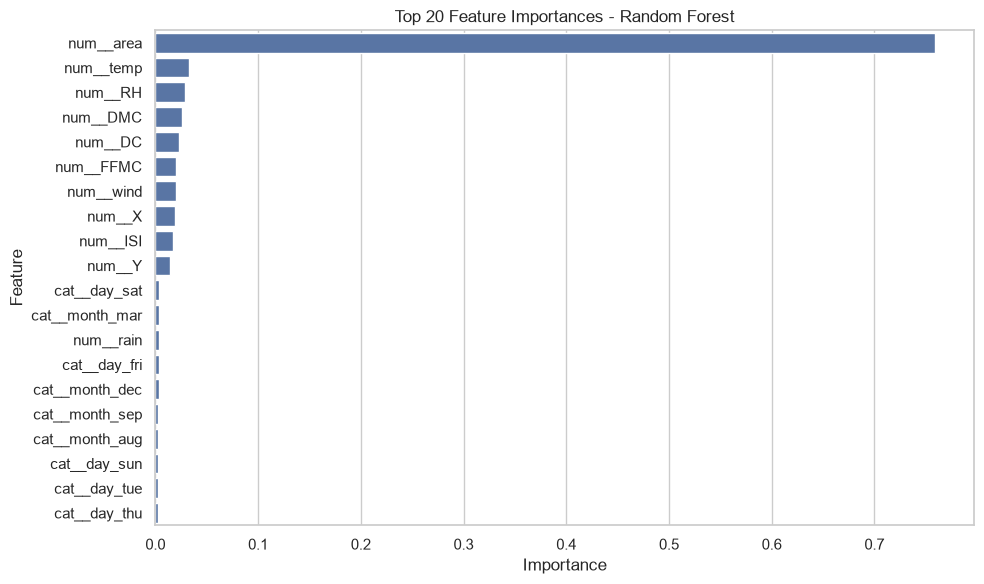

In [20]:
if "Random Forest" in trained_models:
    rf_pipeline = trained_models["Random Forest"]
    fitted_preprocessor = rf_pipeline.named_steps["preprocessor"]
    rf_classifier = rf_pipeline.named_steps["classifier"]

    try:
        feature_names = fitted_preprocessor.get_feature_names_out()
        importances = rf_classifier.feature_importances_
        importance_df = pd.DataFrame({
            "Feature": feature_names,
            "Importance": importances
        }).sort_values("Importance", ascending=False).head(20)

        display(importance_df)
        plt.figure(figsize=(10, 6))
        sns.barplot(data=importance_df, x="Importance", y="Feature")
        plt.title("Top 20 Feature Importances - Random Forest")
        plt.tight_layout()
        plt.show()
    except Exception as e:
        print("Feature importance could not be displayed:", e)
else:
    print("Random Forest model was not trained successfully; skipping feature importance.")

In [21]:
# Working example: predict the class for the first held-out test record.
sample_record = X_test.iloc[[0]].copy()
predicted_encoded = best_model.predict(sample_record)
predicted_class = label_encoder.inverse_transform(predicted_encoded)[0]

print("Input record:")
display(sample_record)
print("Predicted fire-risk class:", predicted_class)

# To enter your own values, replace the sample_record with a one-row DataFrame, e.g.:
# custom_record = pd.DataFrame([{
#     "Temperature": 35,
#     "Humidity": 40,
#     "Wind_Speed": 15
# }])[X.columns]  # Replace these example columns/values with your actual feature columns.
# custom_prediction = best_model.predict(custom_record)
# print("Predicted class:", label_encoder.inverse_transform(custom_prediction)[0])

Input record:


,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
250,8,5,aug,wed,93.1,157.3,666.7,13.5,26.8,25,3.1,0.0,0.68


Predicted fire-risk class: Fire


In [22]:
results_df.to_csv("fire_classification_model_comparison.csv", index=False)
comparison.to_csv("fire_classification_predictions.csv", index=False)

print("Saved:")
print("- fire_classification_model_comparison.csv")
print("- fire_classification_predictions.csv")

Saved:
- fire_classification_model_comparison.csv
- fire_classification_predictions.csv
